In [2]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR  
import math 

from sklearn.model_selection import GroupKFold

base = "/kaggle/input/datasets/tait3r/asl-cleaned/islr_preprocessed"  
data = np.load(f"{base}/landmarks.npy")    
meta = pd.read_csv(f"{base}/meta.csv")
with open(f"{base}/selected_landmarks.json", "r") as f:
  json_data = json.load(f)

## Extract macros from json file

In [3]:
# Prints the first 500 characters nicely formatted
SELECTED = json_data["selected"]
SLICES = {name: slice(a, b) for name, (a, b) in json_data["groups"].items()}
N_LM = len(SELECTED)

In [4]:
print(data.shape)
print(meta.head())

(3583987, 140, 2)
   sequence_id  participant_id   sign  label  offset  length
0   1000035562           26734   blow     25       0      23
1   1000106739           28656   wait    232      23      11
2    100015657           16069  cloud     48      34     105
3   1000210073           25571   bird     23     139      12
4   1000240708           62590   owie    164     151      18


## Split By Signer

Keep some signer out of training to see how well model performs on unseen people

In [5]:
from sklearn.model_selection import GroupKFold
gkf = GroupKFold(n_splits=5)
train_idx, val_idx = next(gkf.split(meta, groups=meta["participant_id"]))

## Drop No Hand Frames and Determine Standard Length of Clip

95th percentile: 80 -> max_len = 80
clips that will be resampled down: 5.0%


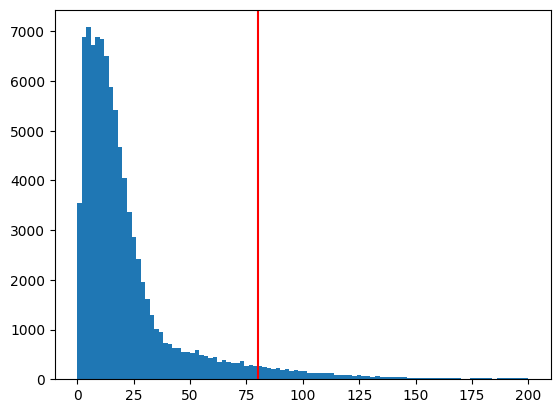

In [6]:
RH = SLICES["right_hand"]

def drop_no_hand(clip):
    hand_present = ~np.isnan(clip[:, RH, 0]).all(axis=1)
    if hand_present.sum() == 0:
        return clip
    return clip[hand_present]

clip_len = np.empty(len(meta), dtype=np.int32)
for i, (o, l) in enumerate(zip(meta["offset"], meta["length"])):
    clip = np.asarray(data[o:o+l], dtype=np.float32)
    clip_len[i] = len(drop_no_hand(clip))

p95 = int(np.percentile(clip_len, 95))
max_len = int(np.ceil(p95 / 16) * 16)    # round up to a multiple of 16
print(f"95th percentile: {p95} -> max_len = {max_len}")
print(f"clips that will be resampled down: {(clip_len > max_len).mean():.1%}")
plt.hist(clip_len, bins=100, range=(0, 200)); plt.axvline(max_len, color="r"); plt.show()

## Normalize and Pad

In [7]:
LH = SLICES["left_hand"]
ARMS = SLICES["arms"]

# change speed of clip given factor n 
def resample(clip, n):
    idx = np.linspace(0, len(clip) - 1, n).astype(int)
    return clip[idx]

def normalize(clip):
    sh = clip[: ,ARMS][:, :2]
    center = np.nanmean(sh, axis=(0, 1))
    scale = np.nanmean(np.linalg.norm(sh[:, 0] - sh[:, 1], axis=-1))
    if not np.isfinite(scale) or scale < 1e-3:
        center = np.nanmean(clip, axis=(0, 1))
        scale = np.nanstd(clip)
    return (clip - center) / scale

def augment(clip, rng):
    # change speed of clip
    new_T = max(2, int(round(len(clip) * rng.uniform(0.8, 1.2))))
    clip = resample(clip, new_T)
    # rotation + scale + shift (coords are centered, units = shoulder width)
    a, s = np.deg2rad(rng.uniform(-15, 15)), rng.uniform(0.9, 1.1)
    R = s * np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]], dtype=np.float32)
    clip = clip @ R.T + rng.uniform(-0.1, 0.1, size=2).astype(np.float32)
    # occasionally blank the non-dominant hand
    if rng.random() < 0.1:
        clip = clip.copy()
        clip[:, LH] = np.nan
    return clip

# add a velocity matrix and a flag that states if non dominant hand is present or not
def to_features(clip):
    T = len(clip)
    vel = np.diff(clip, axis=0, prepend=clip[:1])
    lh_flag = (~np.isnan(clip[:, LH, 0]).all(axis=1)).astype(np.float32)[:, None]
    feats = np.concatenate([clip.reshape(T, -1), vel.reshape(T, -1), lh_flag], axis=1)
    return np.nan_to_num(feats, nan=0.0)
    

In [8]:
class SignDataset(torch.utils.data.Dataset):
    def __init__(self, data, meta, max_len, train):
        self.data, self.meta = data, meta.reset_index(drop=True)
        self.max_len, self.train = max_len, train
        self.rng = np.random.default_rng()

    def __len__(self):
        return len(self.meta)

    def __getitem__(self, i):
        row = self.meta.iloc[i]
        clip = np.asarray(self.data[row.offset : row.offset + row.length], dtype=np.float32)
        clip = drop_no_hand(clip)
        clip = normalize(clip)
        if self.train:
            clip = augment(clip, self.rng)
        if len(clip) > self.max_len:
            clip = resample(clip, self.max_len)
        return torch.from_numpy(to_features(clip)), int(row.label)

def worker_init_fn(_):
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.default_rng(info.seed)

## More Data Setup

In [9]:
BATCH_SIZE = 128

train_meta = meta.iloc[train_idx].reset_index(drop=True)
val_meta   = meta.iloc[val_idx].reset_index(drop=True)

train_ds = SignDataset(data, train_meta, max_len, train=True)
val_ds   = SignDataset(data, val_meta,   max_len, train=False)

# collate pads per batch and adds flag matrice for which frames are padding
def collate(batch):
    xs, ys = zip(*batch)                                
    T = max(x.shape[0] for x in xs)
    F = xs[0].shape[1]
    x = torch.zeros(len(xs), T, F)
    pad_mask = torch.ones(len(xs), T, dtype=torch.bool)  
    for i, xi in enumerate(xs):
        x[i, :len(xi)] = xi
        pad_mask[i, :len(xi)] = False
    return x, pad_mask, torch.tensor(ys, dtype=torch.long)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
     num_workers = 2, collate_fn=collate, worker_init_fn=worker_init_fn,
     pin_memory=True, persistent_workers=True,
)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=4, collate_fn=collate,
    pin_memory=True, persistent_workers=True,
)

## Define Model

In [10]:
class SignTransformer(nn.Module):
    def __init__(self, in_dim, d=192, layers=4, heads=4, n_cls=250, max_len=64):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(in_dim, d), nn.LayerNorm(d), nn.GELU(), nn.Linear(d, d))
        self.pos = nn.Parameter(torch.zeros(1, max_len, d))
        nn.init.trunc_normal_(self.pos, std=0.02)                
        enc = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.2, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(enc, layers, norm=nn.LayerNorm(d))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(d, n_cls))

    def forward(self, x, pad_mask):
        h = self.embed(x) + self.pos[:, :x.size(1)]
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        keep = (~pad_mask).unsqueeze(-1).to(h.dtype)
        h = (h * keep).sum(1) / keep.sum(1).clamp(min=1)
        return self.head(h)

## Training Loop

In [12]:
from torch.utils.data import Subset
tiny = Subset(SignDataset(data, train_meta, max_len, train=False), range(256))
tiny_loader = DataLoader(tiny, batch_size=64, shuffle=True, collate_fn=collate)
# run the training loop below on tiny_loader for ~100 epochs with dropout as-is

device = "cuda"
EPOCHS, W_EPOCHS, LR = 100, 5, 1e-3

model = SignTransformer(in_dim=N_LM*2*2+1, max_len=max_len).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optim = AdamW(model.parameters(), lr=LR, weight_decay=0.05)

steps_per_epoch = len(tiny_loader)
total, warmup = EPOCHS * steps_per_epoch, W_EPOCHS * steps_per_epoch

def lr_lambda(step):
    if step < warmup:
        return (step + 1) / warmup
    progress = (step - warmup) / max(1, total - warmup)
    return 0.5 * (1 + math.cos(math.pi * progress))
    
scheduler = LambdaLR(optim, lr_lambda) # learning rate scheduler, slow down over time
scaler = torch.amp.GradScaler("cuda") # scale the loss to avoid underflow

@torch.no_grad
def evaluate(loader):
    model.eval()
    correct = n = 0
    loss_sum = 0.0
    for x, pad_mask, y in loader:
        x, pad_mask, y = x.to(device, non_blocking=True), pad_mask.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x, pad_mask)
            loss_sum += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, correct / n

best_acc = 0.0
for epoch in range(EPOCHS):
    model.train()
    tr_loss = tr_correct = tr_n = 0
    for x, pad_mask, y in tiny_loader:
        x, pad_mask, y = x.to(device, non_blocking=True), pad_mask.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x, pad_mask)
            loss = criterion(logits, y)
        optim.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optim)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optim)
        scaler.update()
        scheduler.step()

        tr_loss += loss.item() * len(y)
        tr_correct += (logits.argmax(1) == y).sum().item()
        tr_n += len(y)

    val_loss, val_acc = evaluate(tiny_loader)
    print(f"ep {epoch:3d} | train loss {tr_loss/tr_n:.3f} acc {tr_correct/tr_n:.3f} "
              f"| val loss {val_loss:.3f} acc {val_acc:.3f} | lr {scheduler.get_last_lr()[0]:.2e}")

/tmp/ipykernel_49/314377698.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(enc, layers, norm=nn.LayerNorm(d))


ep   0 | train loss 5.694 acc 0.004 | val loss 5.459 acc 0.008 | lr 2.50e-04
ep   1 | train loss 5.509 acc 0.000 | val loss 5.281 acc 0.031 | lr 4.50e-04
ep   2 | train loss 5.349 acc 0.027 | val loss 5.119 acc 0.051 | lr 6.50e-04
ep   3 | train loss 5.219 acc 0.027 | val loss 4.933 acc 0.074 | lr 8.50e-04
ep   4 | train loss 5.036 acc 0.031 | val loss 4.730 acc 0.070 | lr 1.00e-03
ep   5 | train loss 4.801 acc 0.062 | val loss 4.548 acc 0.094 | lr 1.00e-03
ep   6 | train loss 4.578 acc 0.090 | val loss 4.340 acc 0.168 | lr 9.99e-04
ep   7 | train loss 4.448 acc 0.125 | val loss 4.149 acc 0.199 | lr 9.98e-04
ep   8 | train loss 4.267 acc 0.137 | val loss 4.060 acc 0.160 | lr 9.96e-04
ep   9 | train loss 4.146 acc 0.156 | val loss 3.870 acc 0.238 | lr 9.93e-04
ep  10 | train loss 3.956 acc 0.219 | val loss 3.697 acc 0.293 | lr 9.90e-04
ep  11 | train loss 3.812 acc 0.223 | val loss 3.526 acc 0.336 | lr 9.87e-04
ep  12 | train loss 3.663 acc 0.289 | val loss 3.390 acc 0.391 | lr 9.83e-04

In [13]:
device = "cuda"
EPOCHS, W_EPOCHS, LR = 100, 5, 1e-3

model = SignTransformer(in_dim=N_LM*2*2+1, max_len=max_len).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optim = AdamW(model.parameters(), lr=LR, weight_decay=0.05)

steps_per_epoch = len(train_loader)
total, warmup = EPOCHS * steps_per_epoch, W_EPOCHS * steps_per_epoch

def lr_lambda(step):
    if step < warmup:
        return (step + 1) / warmup
    progress = (step - warmup) / max(1, total - warmup)
    return 0.5 * (1 + math.cos(math.pi * progress))
    
scheduler = LambdaLR(optim, lr_lambda) # learning rate scheduler, slow down over time
scaler = torch.amp.GradScaler("cuda") # scale up all weights to avoid vanishing gradient

@torch.no_grad
def evaluate(loader):
    model.eval()
    correct = n = 0
    loss_sum = 0.0
    for x, pad_mask, y in loader:
        x, pad_mask, y = x.to(device, non_blocking=True), pad_mask.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x, pad_mask)
            loss_sum += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, correct / n

best_acc = 0.0
for epoch in range(EPOCHS):
    model.train()
    tr_loss = tr_correct = tr_n = 0
    for x, pad_mask, y in train_loader:
        x, pad_mask, y = x.to(device, non_blocking=True), pad_mask.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x, pad_mask)
            loss = criterion(logits, y)
        optim.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optim)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optim)
        scaler.update()
        scheduler.step()

        tr_loss += loss.item() * len(y)
        tr_correct += (logits.argmax(1) == y).sum().item()
        tr_n += len(y)

    val_loss, val_acc = evaluate(val_loader)
    print(f"ep {epoch:3d} | train loss {tr_loss/tr_n:.3f} acc {tr_correct/tr_n:.3f} "
              f"| val loss {val_loss:.3f} acc {val_acc:.3f} | lr {scheduler.get_last_lr()[0]:.2e}")
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "/kaggle/working/best.pt")

/tmp/ipykernel_49/314377698.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(enc, layers, norm=nn.LayerNorm(d))


ep   0 | train loss 5.040 acc 0.060 | val loss 4.370 acc 0.169 | lr 2.00e-04
ep   1 | train loss 3.699 acc 0.285 | val loss 3.617 acc 0.304 | lr 4.00e-04
ep   2 | train loss 2.980 acc 0.432 | val loss 3.402 acc 0.355 | lr 6.00e-04
ep   3 | train loss 2.706 acc 0.492 | val loss 3.242 acc 0.397 | lr 8.00e-04
ep   4 | train loss 2.559 acc 0.530 | val loss 3.167 acc 0.420 | lr 1.00e-03
ep   5 | train loss 2.425 acc 0.567 | val loss 3.099 acc 0.447 | lr 1.00e-03
ep   6 | train loss 2.266 acc 0.608 | val loss 3.022 acc 0.461 | lr 9.99e-04
ep   7 | train loss 2.152 acc 0.642 | val loss 3.180 acc 0.437 | lr 9.98e-04
ep   8 | train loss 2.068 acc 0.666 | val loss 2.954 acc 0.488 | lr 9.96e-04
ep   9 | train loss 2.000 acc 0.685 | val loss 2.996 acc 0.478 | lr 9.93e-04
ep  10 | train loss 1.939 acc 0.703 | val loss 2.895 acc 0.504 | lr 9.90e-04
ep  11 | train loss 1.887 acc 0.717 | val loss 2.880 acc 0.506 | lr 9.87e-04
ep  12 | train loss 1.842 acc 0.731 | val loss 2.839 acc 0.509 | lr 9.83e-04

Exception in thread Thread-5 (_pin_memory_loop):


KeyboardInterrupt: 

Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 52, in _pin_memory_loop
    do_one_step()
    ~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 28, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 120, in get
    return _ForkingPickler.loads(res)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/multiprocessing/reductions.py", line 540, in rebuild_storage_fd
    fd = df.detach()
  File "/usr/lib/python3.13/multiprocessing/resource_sharer.py", line 57, in detach
    with _resourc